# 07 Hotspots Finden

Das Stadtgebiet wird in ein Raster von ca. 1 km x 1 km eingeteilt. Je Zelle werden Unfälle, schwere Unfälle und der Ueberschuss gegenüber dem stadtweiten Durchschnitt berechnet.

Hotspots sind die drei Zellen mit dem groessten Überschuss (mindestens 20 Unfälle). Für jeden Hotspot wird `massnahmen_empfehlen()` angewendet. Zu jedem Hotspot werden drei Kontrollzellen gewaehlt

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from katalog import katalog, massnahmen_empfehlen

df_clean  = pd.read_parquet('../../data/df_features_gps.parquet')
df_unfall = pd.read_parquet('../../data/df_unfall_gps.parquet')

bu, bf = df_unfall['schwer'].mean(), df_clean['schwer'].mean()
print('df_unfall:', len(df_unfall), '| df_clean:', len(df_clean))

df_unfall: 9517 | df_clean: 12316


In [44]:
# Raster ca. 1 km x 1 km (0,009 Grad = ca. 1 km)
GRID = 0.009
def zelle(lat, lon):
    return (np.floor(lat / GRID).astype(int).astype(str) + '_' +
            np.floor(lon / GRID).astype(int).astype(str))

df_unfall['Zelle'] = zelle(df_unfall['Lat'], df_unfall['Lon'])
df_clean = df_clean.drop(columns=['Zelle'], errors='ignore').merge(
    df_unfall[['Unfall_ID', 'Zelle']], on='Unfall_ID', how='left')

zellen = df_unfall.groupby('Zelle').agg(
    n=('schwer', 'size'), schwer=('schwer', 'sum'),
    lat=('Lat', 'mean'), lon=('Lon', 'mean'))
zellen['anteil'] = (zellen['schwer'] / zellen['n'] * 100).round(1)
zellen['ueberschuss'] = (zellen['schwer'] - zellen['n'] * bu).round(1)

MIN_N = 20
hotspots = (zellen[zellen['n'] >= MIN_N]
            .sort_values('ueberschuss', ascending=False).head(3).copy())
hotspots['Hotspot'] = ['HS1', 'HS2', 'HS3']
print(f'Zellen gesamt: {len(zellen)}, davon mit mindestens {MIN_N} Unfaellen: {(zellen["n"] >= MIN_N).sum()}')
hotspots

Zellen gesamt: 570, davon mit mindestens 20 Unfaellen: 109


,n,schwer,lat,lon,anteil,ueberschuss,Hotspot
Zelle,,,,,,,
1002_4307,128,30,9.022308,38.767257,23.4,8.8,HS1
998_4309,122,28,8.987192,38.785220,23.0,7.8,HS2
1003_4320,75,19,9.031411,38.880000,25.3,6.6,HS3


In [45]:
# Massnahmenempfehlung je Hotspot
empf_hs = {}
for z, r in hotspots.iterrows():
    unf = df_unfall[df_unfall['Zelle'] == z]
    fzg = df_clean[df_clean['Zelle'] == z]
    e = massnahmen_empfehlen(unf, fzg, katalog, min_n=5, basis_unf=bu, basis_fzg=bf)
    empf_hs[r['Hotspot']] = e
    print(f'\n=== {r["Hotspot"]} ({r["n"]:.0f} Unfaelle, {r["schwer"]:.0f} schwer, Ueberschuss +{r["ueberschuss"]:.0f}) ===')
    display(e[['ID', 'Situation', 'n', 'Anteil_schwer_%', 'Ueberschuss', 'Massnahme']].head(3)
            if len(e) else 'keine Massnahme mit Ueberschuss')

hotspots['Massnahme_ID'] = [empf_hs[h]['ID'].iloc[0] for h in hotspots['Hotspot']]
hotspots[['Hotspot', 'n', 'schwer', 'anteil', 'ueberschuss', 'Massnahme_ID']]


=== HS1 (128 Unfaelle, 30 schwer, Ueberschuss +9) ===


,ID,Situation,n,Anteil_schwer_%,Ueberschuss,Massnahme
Prio,,,,,,
1,M4,Überholen / Fahren auf der Gegenspur,6,50.0,2,"Überholverbote, Mittelleitplanken"
2,M1,Abend/Nacht (20–5 Uhr) in Büro-/Wohngebieten,17,23.5,1,"Abendliche Geschwindigkeitskontrollen, Tempo 3..."
3,M3,Fahrer unter 18 Jahren,9,22.2,1,"Führerscheinkontrollen, Halterhaftung"



=== HS2 (122 Unfaelle, 28 schwer, Ueberschuss +8) ===


,ID,Situation,n,Anteil_schwer_%,Ueberschuss,Massnahme
Prio,,,,,,
1,M1,Abend/Nacht (20–5 Uhr) in Büro-/Wohngebieten,21,42.9,6,"Abendliche Geschwindigkeitskontrollen, Tempo 3..."
2,M7,Freie Strecke (kein Knotenpunkt) abends/nachts,7,71.4,4,"Streckenbezogene Geschwindigkeitsüberwachung, ..."
3,M4,Überholen / Fahren auf der Gegenspur,5,20.0,0,"Überholverbote, Mittelleitplanken"



=== HS3 (75 Unfaelle, 19 schwer, Ueberschuss +7) ===


,ID,Situation,n,Anteil_schwer_%,Ueberschuss,Massnahme
Prio,,,,,,
1,M2,Kollision mit Objekten am Straßenrand,18,33.3,3,"Schutzplanken, Leitpfosten, Absicherung von Hi..."
2,M3,Fahrer unter 18 Jahren,10,30.0,1,"Führerscheinkontrollen, Halterhaftung"
3,M7,Freie Strecke (kein Knotenpunkt) abends/nachts,5,20.0,0,"Streckenbezogene Geschwindigkeitsüberwachung, ..."


,Hotspot,n,schwer,anteil,ueberschuss,Massnahme_ID
Zelle,,,,,,
1002_4307,HS1,128,30,23.4,8.8,M4
998_4309,HS2,122,28,23.0,7.8,M1
1003_4320,HS3,75,19,25.3,6.6,M2


In [46]:
# Kontrollzellen: je Hotspot 3 Zellen mit aehnlicher Unfallzahl, ohne auffaelligen Ueberschuss
kandidaten = zellen[(~zellen.index.isin(hotspots.index)) & (zellen['n'] >= MIN_N)
                    & (zellen['ueberschuss'].abs() <= 3)].copy()
kontrolle = {}
for z, r in hotspots.iterrows():
    k = kandidaten.assign(diff=(kandidaten['n'] - r['n']).abs()).sort_values('diff').head(3)
    kontrolle[r['Hotspot']] = list(k.index)
    kandidaten = kandidaten.drop(k.index)
for h, ks in kontrolle.items():
    print(h, '-> Kontrollzellen:', ks, '| n =', list(zellen.loc[ks, 'n']))

HS1 -> Kontrollzellen: ['1000_4304', '999_4308', '1000_4309'] | n = [129, 134, 107]
HS2 -> Kontrollzellen: ['1003_4305', '1000_4310', '998_4310'] | n = [104, 101, 99]
HS3 -> Kontrollzellen: ['1003_4319', '1002_4315', '995_4305'] | n = [72, 71, 71]


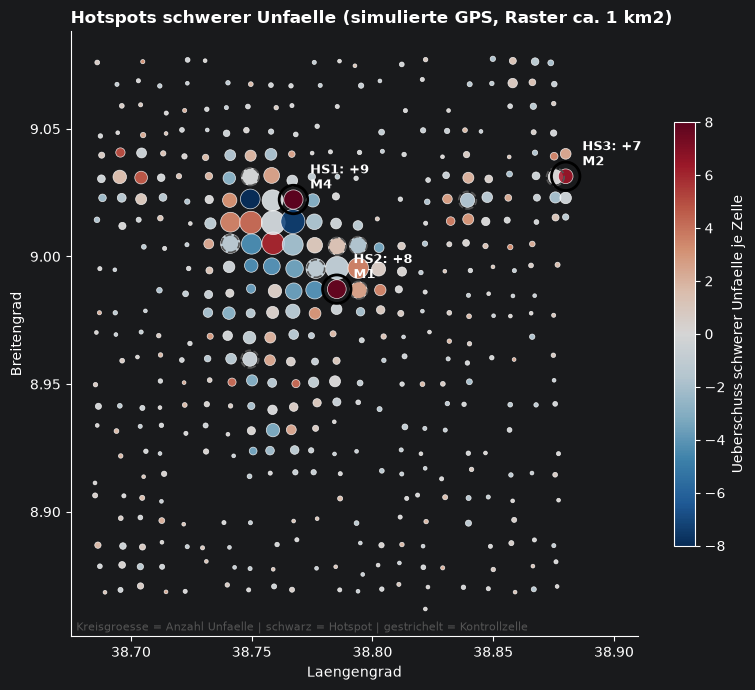

In [47]:
fig, ax = plt.subplots(figsize=(8, 7))
z = zellen[zellen['n'] >= 5]
sc = ax.scatter(z['lon'], z['lat'], c=z['ueberschuss'],
                s=np.clip(z['n'], 5, 200) * 1.5,
                cmap='RdBu_r', vmin=-8, vmax=8, alpha=0.85,
                edgecolor='white', linewidth=0.5)
for h, ks in kontrolle.items():
    ax.scatter(zellen.loc[ks, 'lon'], zellen.loc[ks, 'lat'],
               s=160, facecolor='none', edgecolor='#555', lw=1.2, ls='--')
for _, r in hotspots.iterrows():
    ax.scatter(r['lon'], r['lat'], s=420, facecolor='none', edgecolor='black', lw=2)
    ax.annotate(f'{r["Hotspot"]}: +{r["ueberschuss"]:.0f}\n{r["Massnahme_ID"]}',
                (r['lon'], r['lat']), xytext=(12, 8), textcoords='offset points',
                fontsize=9, fontweight='bold')
plt.colorbar(sc, ax=ax, label='Ueberschuss schwerer Unfaelle je Zelle', shrink=0.7)
ax.set_xlim(38.675, 38.91)
ax.set_xlabel('Laengengrad'); ax.set_ylabel('Breitengrad')
ax.set_title('Hotspots schwerer Unfaelle (simulierte GPS, Raster ca. 1 km2)',
             loc='left', fontweight='bold')
ax.text(0.01, 0.01,
        'Kreisgroesse = Anzahl Unfaelle | schwarz = Hotspot | gestrichelt = Kontrollzelle',
        transform=ax.transAxes, fontsize=8, color='#555')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Ergebnis:** Von 570 Zellen haben 109 mindestens 20 Unfälle. Für jede Zelle wird automatisch die passende Maßnahme vorgeschlagen.

## Speichern

In [48]:
import json

zellen.to_parquet('../../data/zellen.parquet')
hotspots.to_parquet('../../data/hotspots.parquet')
with open('../../data/kontrolle.json', 'w') as f:
    json.dump(kontrolle, f)

# df_unfall mit Zelle-Spalte zurückspeichern, damit 08_simulation_result.ipynb sie laden kann
df_unfall.to_parquet('../../data/df_unfall_gps.parquet', index=False)
df_clean.to_parquet('../../data/df_features_gps.parquet', index=False)
print('Gespeichert: zellen.parquet, hotspots.parquet, kontrolle.json')
print('Aktualisiert: df_unfall_gps.parquet (mit Zelle), df_features_gps.parquet (mit Zelle)')

Gespeichert: zellen.parquet, hotspots.parquet, kontrolle.json
Aktualisiert: df_unfall_gps.parquet (mit Zelle), df_features_gps.parquet (mit Zelle)
